# Lab 10: Odometry vs. odometry + gyro localization
The robot drove the digit **32** twice with `lab10_odometry_gyro.qrs`: run A with `MODE = 1` (course from the encoders) and run B with `MODE = 2` (course from the gyro). This notebook reads both logs, repeats the robot's localization offline with both methods, and makes the plots and the comparison table of the README.

Upload the two logs from the robot: `lab10_run_A.txt` and `lab10_run_B.txt`.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving lab10_run_A.txt to lab10_run_A.txt
Saving lab10_run_B.txt to lab10_run_B.txt


In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
r = 4.3                                             # wheel radius, cm
B = 19.6                                            # wheel base, cm
s = -0.047                                          # gyro scale factor
X_ref = np.array([0, 30, 30, 0, 30, 30, 0, 50, 80, 80, 50, 50, 80])                 # start point and 12 waypoints, cm
Y_ref = np.array([0, 0, 30, 30, 30, 60, 60, 60, 60, 30, 30, 0, 0])
course_ref = np.arctan2(np.diff(Y_ref), np.diff(X_ref))                             # ideal course of every segment, rad
path_ref = np.hypot(np.diff(X_ref), np.diff(Y_ref))                                 # ideal length of every segment, cm
name = {1: 'encoders', 2: 'gyro'}                   # course source for MODE = 1 and MODE = 2

def wrap(angle):
    return (angle + np.pi) % (2 * np.pi) - np.pi    # angle to [-pi, pi)

**Logs.** Every line of a log is one control cycle of the robot, written by the program as `t, i, theta_l, theta_r, gz, gt, x, y, course`:
- `t`: time, `time()`, in ms.
- `i`: index of the target waypoint, 0 to 11; −1 during the 10 s at rest.
- `theta_l`, `theta_r`: left (encoder E4) and right (encoder E3) wheel angles, in rad.
- `gz`: gyro turning rate around the vertical axis, `gyroscope[2]`, in mdeg/s.
- `gt`: gyro timestamp, `gyroscope[3]`, in units of 256 µs. The difference of two readings times 0.000256 is the time between them in s.
- `x`, `y`: position the robot estimated, in cm.
- `course`: course the robot estimated and steered by, in rad.

Lines with `i = -1` are the 10 s at rest, with 0 in the wheel and pose columns. Their mean `gz` is the gyro bias `b0`, the same value the robot computed before driving. The other lines are the driving: the raw sensors `theta_l, theta_r, gz, gt` are used below to repeat the localization, and `x, y, course` are the robot's own result, used to check it.

In [4]:
def read_log(file):
    t, i, theta_l, theta_r, gz, gt, x, y, course = np.loadtxt(file, delimiter=',', unpack=True)
    rest = i < 0                                    # 10 s at rest
    run = i >= 0                                    # driving
    return {'b0': np.mean(gz[rest]),                # gyro bias, mdeg/s
            'b0_error': np.std(gz[rest]) / np.sqrt(np.sum(rest)),                   # uncertainty of b0, mdeg/s
            't': t[run] / 1000, 'i': i[run].astype(int),                            # time in s, target waypoint
            'theta_l': theta_l[run], 'theta_r': theta_r[run], 'gz': gz[run], 'gt': gt[run],  # raw sensors
            'x': x[run], 'y': y[run], 'course': course[run]}                        # the robot's estimate

log = {'A': read_log('lab10_run_A.txt'), 'B': read_log('lab10_run_B.txt')}          # run A: MODE = 1, run B: MODE = 2
used = {'A': 1, 'B': 2}                             # MODE of each run on the robot

**Offline localization.** `localize` repeats the robot's program line by line, from the raw sensors of a log. In every control cycle `k`:

**Path** of the robot centre, the average of the two wheel arcs:
$$path = (\theta_r + \theta_l)\,\frac{r}{2}$$

**Course from the encoders**, the difference of the two wheel arcs divided by the wheel base:
$$course_{odom} = (\theta_r - \theta_l)\,\frac{r}{B}$$

**Time step** between this gyro reading and the previous one; the gyro timestamp counts in steps of 256 µs:
$$\Delta t = (gt_k - gt_{k-1}) \cdot 0.000256 \text{ s}$$

**Course change from the gyro** in this cycle: the turning rate minus the bias, converted to deg/s, corrected by the scale factor, multiplied by the time step and converted to rad:
$$gyro\_inc = \frac{gz - b_0}{1000\,(1 + s)}\,\Delta t\,\frac{\pi}{180}$$

**Course**, the program's `MODE` line: `MODE = 1` keeps `course_odom` (run A), `MODE = 2` adds `gyro_inc` to the previous course (run B):
$$course = (2 - MODE)\,course_{odom} + (MODE - 1)\,(course + gyro\_inc)$$

**Position**, the path driven in this cycle in the direction of the course:
$$x = x + (path_k - path_{k-1})\cos(course)$$
$$y = y + (path_k - path_{k-1})\sin(course)$$

Running `localize` with both `MODE` values on both logs gives 4 paths. With its own `MODE` a run must give back its logged `x, y, course`; with the other `MODE` it shows what the other sensor would have said.

In [5]:
def localize(d, MODE, s=s):
    n = len(d['t'])                                 # number of control cycles
    path = (d['theta_r'] + d['theta_l']) * r / 2    # path of the robot centre, cm
    course_odom = (d['theta_r'] - d['theta_l']) * r / B                             # course from the encoders, rad
    course = np.zeros(n)                            # course, rad
    x = np.zeros(n)                                 # X coordinate, cm
    y = np.zeros(n)                                 # Y coordinate, cm
    course[0] = (2 - MODE) * course_odom[0]         # first cycle: no gyro time step yet
    x[0] = path[0] * np.cos(course[0])
    y[0] = path[0] * np.sin(course[0])
    for k in range(1, n):
        dt = (d['gt'][k] - d['gt'][k-1]) * 0.000256                                 # time between two gyro readings, s
        gyro_inc = (d['gz'][k] - d['b0']) / 1000 / (1 + s) * dt * np.pi / 180       # course change from the gyro, rad
        course[k] = (2 - MODE) * course_odom[k] + (MODE - 1) * (course[k-1] + gyro_inc)  # the program's MODE line
        x[k] = x[k-1] + (path[k] - path[k-1]) * np.cos(course[k])                   # X coordinate
        y[k] = y[k-1] + (path[k] - path[k-1]) * np.sin(course[k])                   # Y coordinate
    return {'path': path, 'course': course, 'x': x, 'y': y}

P = {}                                              # 4 paths: P[run, MODE]
for run in 'AB':
    for MODE in (1, 2):
        P[run, MODE] = localize(log[run], MODE)

for run in 'AB':
    d, p = log[run], P[run, used[run]]
    print(f"run {run}: driving {d['t'][-1] - d['t'][0]:.0f} s, cycle {1000 * np.median(np.diff(d['t'])):.0f} ms, "
          f"b0 = {d['b0'] / 1000:.3f} ± {d['b0_error'] / 1000:.3f} deg/s, fastest turn {np.max(np.abs(d['gz'])) / 1000:.0f} deg/s")
    print(f"       robot vs. offline: {np.max(np.hypot(d['x'] - p['x'], d['y'] - p['y'])):.3f} cm, "
          f"{np.degrees(np.max(np.abs(d['course'] - p['course']))):.4f} deg")

run A: driving 47 s, cycle 60 ms, b0 = 0.531 ± 0.004 deg/s, fastest turn 91 deg/s
       robot vs. offline: 0.000 cm, 0.0000 deg
run B: driving 52 s, cycle 60 ms, b0 = 0.440 ± 0.003 deg/s, fastest turn 80 deg/s
       robot vs. offline: 0.001 cm, 0.0004 deg


**Trajectories.** The ideal digit with the segment numbers 1 to 12 (written on the left of the travel direction), the logged path of each run (solid), and the same run recomputed with the other `MODE` (dashed). The ends of the 4 paths are printed under the plot.

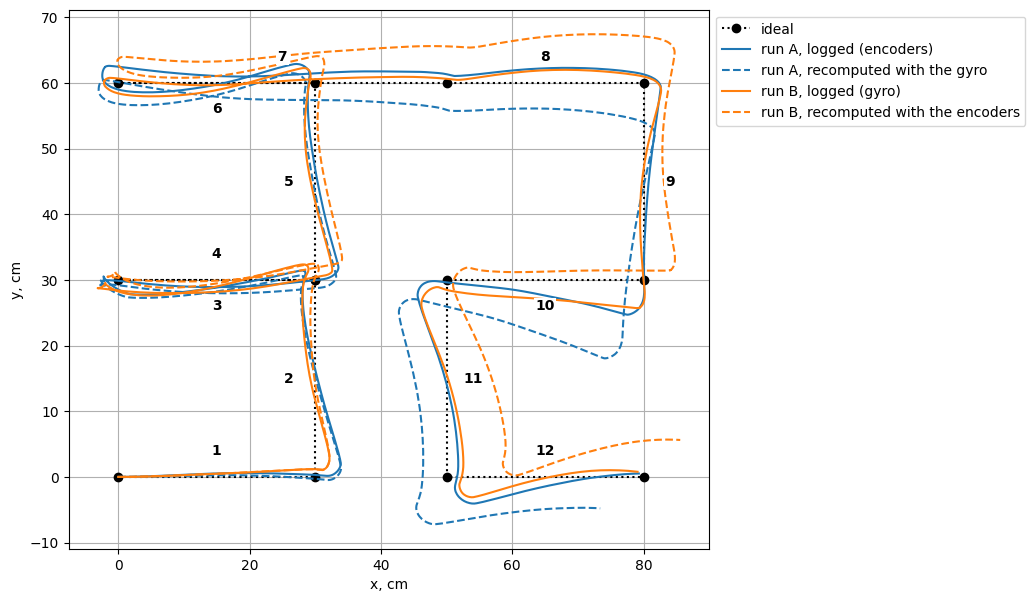

run A, course from the encoders: ends at (79.3, 0.5) cm
run A, course from the gyro: ends at (73.4, -4.8) cm
run B, course from the encoders: ends at (85.6, 5.6) cm
run B, course from the gyro: ends at (79.1, 0.8) cm


In [6]:
plt.figure(figsize=(11, 7))                         # plot window
plt.plot(X_ref, Y_ref, 'k:o', label='ideal')        # ideal digit
for j in range(12):                                 # segment number, 4 cm left of the segment middle
    xm = (X_ref[j] + X_ref[j+1]) / 2 - 4 * (Y_ref[j+1] - Y_ref[j]) / path_ref[j]
    ym = (Y_ref[j] + Y_ref[j+1]) / 2 + 4 * (X_ref[j+1] - X_ref[j]) / path_ref[j]
    plt.text(xm, ym, j + 1, ha='center', va='center', weight='bold', bbox=dict(fc='white', ec='none', pad=1))
for run, color in [('A', 'C0'), ('B', 'C1')]:
    other = 3 - used[run]                           # the other MODE
    plt.plot(log[run]['x'], log[run]['y'], color, label=f'run {run}, logged ({name[used[run]]})')
    plt.plot(P[run, other]['x'], P[run, other]['y'], color + '--', label=f'run {run}, recomputed with the {name[other]}')
plt.axis('scaled'); plt.grid(); plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.show()
for run in 'AB':
    for MODE in (1, 2):
        print(f"run {run}, course from the {name[MODE]}: ends at ({P[run, MODE]['x'][-1]:.1f}, {P[run, MODE]['y'][-1]:.1f}) cm")

**What the plot shows.** Both logged paths (solid) stay close to the digit, because each run steers its own estimate onto the waypoints. The dashed paths show how much the two sensors disagree: recomputed with the other sensor, run A ends at (73.4, −4.8) instead of (79.3, 0.5), and run B at (85.6, 5.6) instead of (79.1, 0.8), about 8 cm apart in both runs. The dashed paths move a little further away at every turn, so the gap grows along the digit and is largest on the 2. Which of the two is right cannot be told from the logs alone; that needs the real end position measured on the floor.

**Comparison table.** For every segment `j` (the cycles with `i = j`):
- `course`: the logged course, averaged over the straight. The straight is the longest stretch of cycles in which both wheels turn forward, so the turn in place, the rolling past the previous waypoint and the last steering onto the waypoint are left out.
- `path`: the path at the end of the segment minus the path at the end of the previous one.
- `d_course = course - course_ref`, `d_path = path - path_ref`.

The table is printed in the README's format. The summary row is mean abs(`d_course`), the total path and the total `d_path` in cm and %. The last lines are the final position and course errors from the logs, relative to the last waypoint (80, 0) and its course 0°.

In [11]:
def segments(d):
    dl = np.diff(d['theta_l'], prepend=0)           # left wheel turn in each cycle
    dr = np.diff(d['theta_r'], prepend=0)           # right wheel turn in each cycle
    path = (d['theta_r'] + d['theta_l']) * r / 2    # path of the robot centre, cm
    course_seg = np.zeros(12)                       # mean course on the straight, deg
    path_seg = np.zeros(12)                         # path of the segment, cm
    for j in range(12):
        rows = np.where(d['i'] == j)[0]             # cycles of segment j
        straight, stretch = [], []                  # longest and current stretch of driving cycles
        for k in rows:
            stretch = stretch + [k] if dl[k] > 0 and dr[k] > 0 else []
            if len(stretch) > len(straight):
                straight = stretch
        course_seg[j] = np.degrees(course_ref[j] + np.mean(wrap(d['course'][straight] - course_ref[j])))
        path_seg[j] = path[rows[-1]] - (path[rows[0] - 1] if j > 0 else 0)
    return course_seg, path_seg

course_seg, path_seg = {}, {}                       # mean course (deg) and path (cm) of every segment
for run in 'AB':
    course_seg[run], path_seg[run] = segments(log[run])
ref = np.degrees(course_ref)                        # ideal course, deg
print('courses in deg, paths in cm\n')
print(f"{'Seg.':>4}{'course_ref':>12}{'course A':>10}{'course B':>10}{'d_course A':>12}{'d_course B':>12}"
      f"{'path_ref':>10}{'path A':>8}{'path B':>8}{'d_path A':>10}{'d_path B':>10}")
for j in range(12):
    cA, cB, pA, pB = course_seg['A'][j], course_seg['B'][j], path_seg['A'][j], path_seg['B'][j]
    print(f'{j + 1:>4}{ref[j]:>12.0f}{cA:>10.1f}{cB:>10.1f}{cA - ref[j]:>+12.1f}{cB - ref[j]:>+12.1f}'
          f'{path_ref[j]:>10.0f}{pA:>8.1f}{pB:>8.1f}{pA - path_ref[j]:>+10.1f}{pB - path_ref[j]:>+10.1f}')
print()
for run in 'AB':
    d, total = log[run], path_seg[run].sum()        # log and total path of the run
    print(f"run {run}: mean abs(d_course) {np.mean(np.abs(course_seg[run] - ref)):.1f} deg, "
          f"total path {total:.1f} of {path_ref.sum():.0f} cm ({total - path_ref.sum():+.1f} cm, {100 * (total / path_ref.sum() - 1):+.1f} %)")
    print(f"       final position error {np.hypot(d['x'][-1] - X_ref[-1], d['y'][-1] - Y_ref[-1]):.1f} cm, "
          f"final course error {np.degrees(wrap(d['course'][-1] - course_ref[-1])):+.1f} deg")

courses in deg, paths in cm

Seg.  course_ref  course A  course B  d_course A  d_course B  path_ref  path A  path B  d_path A  d_path B
   1           0       0.6       2.1        +0.6        +2.1        30    29.9    29.7      -0.1      -0.3
   2          90     101.9     100.0       +11.9       +10.0        30    33.3    31.0      +3.3      +1.0
   3         180     187.5     188.9        +7.5        +8.9        30    30.4    31.9      +0.4      +1.9
   4           0      -0.4       2.6        -0.4        +2.6        30    34.4    34.0      +4.4      +4.0
   5          90      99.6      97.3        +9.6        +7.3        30    33.1    31.6      +3.1      +1.6
   6         180     188.2     188.4        +8.2        +8.4        30    31.7    31.9      +1.7      +1.9
   7           0      -1.6      -0.1        -1.6        -0.1        50    57.0    55.2      +7.0      +5.2
   8           0       0.7       1.3        +0.7        +1.3        30    30.5    30.5      +0.5      +0.5
   9    

**Course and error growth.** Top: the course of each run from the encoders and from the gyro, over the ideal course `course_ref` (a staircase). Bottom: `d_course` of every segment and the largest distance from the logged `x, y` to the ideal segment.

run A, largest distance to the ideal segment, cm: [0.6 3.9 2.2 1.3 3.5 2.9 2.6 2.3 2.6 5.3 4.4 4.1]
run B, largest distance to the ideal segment, cm: [1.2 2.2 2.4 2.  2.6 2.3 1.6 2.  2.7 4.3 3.8 3.1]


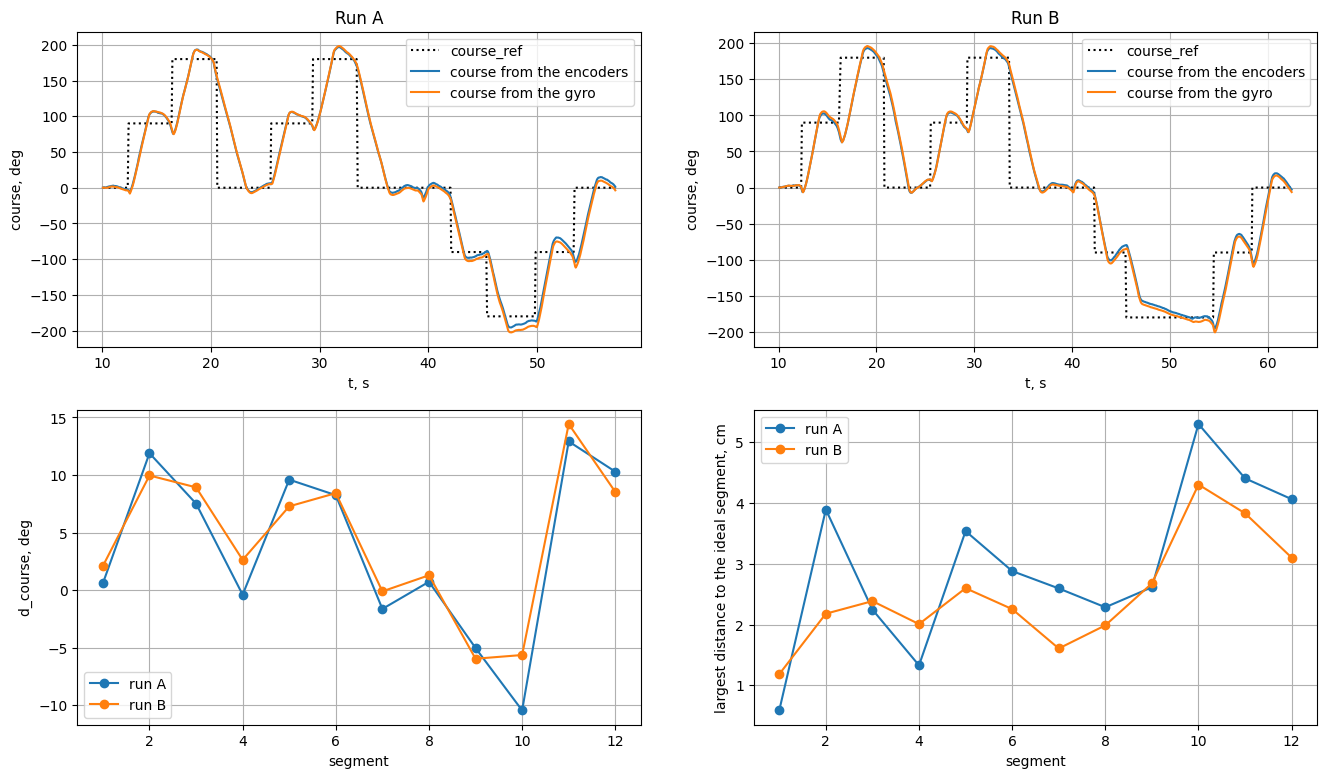

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(16, 9))       # plot window: 2 x 2
for col, run in enumerate('AB'):
    d = log[run]
    staircase = d['course'] + wrap(course_ref[d['i']] - d['course'])                # course_ref next to the course, rad
    ax[0, col].plot(d['t'], np.degrees(staircase), 'k:', label='course_ref')
    ax[0, col].plot(d['t'], np.degrees(P[run, 1]['course']), label='course from the encoders')
    ax[0, col].plot(d['t'], np.degrees(P[run, 2]['course']), label='course from the gyro')
    ax[0, col].set(title=f'Run {run}', xlabel='t, s', ylabel='course, deg')
    dx, dy = np.diff(X_ref)[d['i']], np.diff(Y_ref)[d['i']]                         # direction of the segment being driven
    off = np.abs(dx * (d['y'] - Y_ref[d['i']]) - dy * (d['x'] - X_ref[d['i']])) / np.hypot(dx, dy)  # distance to it, cm
    off_max = [np.max(off[d['i'] == j]) for j in range(12)]                         # largest distance in every segment, cm
    ax[1, 0].plot(range(1, 13), course_seg[run] - ref, '-o', label=f'run {run}')
    ax[1, 1].plot(range(1, 13), off_max, '-o', label=f'run {run}')
    print(f'run {run}, largest distance to the ideal segment, cm:', np.round(off_max, 1))
ax[1, 0].set(xlabel='segment', ylabel='d_course, deg')
ax[1, 1].set(xlabel='segment', ylabel='largest distance to the ideal segment, cm')
for a in ax.flat:
    a.grid(); a.legend()
plt.show()

**Error source.** Total rotation measured by the encoders and by the raw gyro (`s = 0`) during the turns in place, and their difference on the straights. A gyro bias would show everywhere, also on the straights; a difference only in the turns comes from `B`, the gyro scale factor or wheel slip.

In [13]:
for run in 'AB':
    d = log[run]
    dl, dr = np.diff(d['theta_l'], prepend=0), np.diff(d['theta_r'], prepend=0)     # wheel turns in each cycle
    turn = dl * dr < 0                              # turning in place: wheels in opposite directions
    straight = (dl > 0) & (dr > 0)                  # driving: both wheels forward
    enc = np.degrees(np.diff(P[run, 1]['course'], prepend=0))                       # course change from the encoders, deg
    gyr = np.degrees(np.diff(localize(d, 2, s=0)['course'], prepend=0))             # course change from the raw gyro, deg
    enc_turn, gyr_turn = np.sum(np.abs(enc[turn])), np.sum(np.abs(gyr[turn]))       # total rotation in the turns, deg
    print(f'run {run}: turns: encoders {enc_turn:.0f} deg, gyro {gyr_turn:.0f} deg ({100 * (enc_turn / gyr_turn - 1):+.1f} %), '
          f'straights: encoders - gyro {np.sum(enc[straight] - gyr[straight]):+.1f} deg')

run A: turns: encoders 1196 deg, gyro 1158 deg (+3.3 %), straights: encoders - gyro +2.1 deg
run B: turns: encoders 1213 deg, gyro 1173 deg (+3.4 %), straights: encoders - gyro -2.6 deg


**Conclusion.** The gyro (run B) gives the better course. In the logs run B is slightly closer to the ideal digit: mean abs(`d_course`) 6.3° vs 6.6°, path +6.8 % vs +8.9 %. The gyro measures the rotation of the robot body directly, so wheel slip and `B` do not affect it; after the 10 s calibration its bias adds only about 0.2° per run, and it never saturated. The encoders see only the wheels, and in the turns they differ from the gyro by about 3 %. The margin is small, and in longer runs the gyro bias would drift, so the best course combines both sensors (Lab 11).